# Orchestration

### This is our first agentic-framework based project.

This lab has 3 parts:
- Part 1: Email Setup
- Part 2: Orchestrating by code
- Part 3: Orchestrating by LLMs

In [28]:
# Imports

from dotenv import load_dotenv
import os
from email.message import EmailMessage
import smtplib
from agents import Agent, Runner, trace, function_tool, ModelSettings
from agents.extensions.visualization import draw_graph
from openai.types.responses import ResponseTextDeltaEvent
import asyncio
load_dotenv(override=True)
MODEL_NAME = "gpt-5.4-mini"


## Part 1: Email Setup

In [3]:
EMAIL_ADDRESS       = os.getenv("EMAIL_ADDRESS")
EMAIL_SMTP_SERVER   = os.getenv("EMAIL_SMTP_SERVER")
EMAIL_APP_PASSWORD  = os.getenv("EMAIL_APP_PASSWORD")

if EMAIL_ADDRESS:
    print("Email address is set")
else:
    print("Email address is not set")

if EMAIL_SMTP_SERVER:
    print("SMTP server is set")
else:
    print("SMTP server is not set")

if EMAIL_APP_PASSWORD:
    print("Email password is set")
else:
    print("Email password is not set")

USE_EMAIL = EMAIL_ADDRESS and EMAIL_APP_PASSWORD and EMAIL_APP_PASSWORD

if USE_EMAIL:
    print("Email is set and we will try using it")
else:
    print("Email is not set; we will send push notification instead")

print(EMAIL_ADDRESS)


Email address is set
SMTP server is set
Email password is set
Email is set and we will try using it
kasamsantosh71@gmail.com


In [4]:
msg1 = EmailMessage()
help(msg1)

Help on EmailMessage in module email.message object:

class EmailMessage(MIMEPart)
 |  EmailMessage(policy=None)
 |
 |  Method resolution order:
 |      EmailMessage
 |      MIMEPart
 |      Message
 |      builtins.object
 |
 |  Methods defined here:
 |
 |  set_content(self, *args, **kw)
 |
 |  ----------------------------------------------------------------------
 |  Methods inherited from MIMEPart:
 |
 |  __init__(self, policy=None)
 |      Initialize self.  See help(type(self)) for accurate signature.
 |
 |  __str__(self)
 |      Return the entire formatted message as a string.
 |
 |  add_alternative(self, *args, **kw)
 |
 |  add_attachment(self, *args, **kw)
 |
 |  add_related(self, *args, **kw)
 |
 |  as_string(self, unixfrom=False, maxheaderlen=None, policy=None)
 |      Return the entire formatted message as a string.
 |
 |      Optional 'unixfrom', when true, means include the Unix From_ envelope
 |      header.  maxheaderlen is retained for backward compatibility with the
 | 

In [5]:
# Define send_email function

def send_email(subject: str, text_body: str, html_body: str):
    # Create a message object from EmailMessage() class
    msg = EmailMessage()
    
    msg["From"] = EMAIL_ADDRESS
    msg["To"]   = EMAIL_ADDRESS
    msg["Subject"] = subject
    msg.set_content(text_body)
    msg.add_alternative(html_body, subtype="html")

    with smtplib.SMTP(EMAIL_SMTP_SERVER, 587) as server:
        server.starttls()
        server.login(EMAIL_ADDRESS, EMAIL_APP_PASSWORD)
        server.send_message(msg)



In [6]:
send_email("test123", "Namaskaram ra batta", "<html><body><strong>Namaskaram</strong> ra batta</body></html>")

In [7]:
# USE_EMAIL = False

### Fallback - Push notifications

In [8]:
pushover_user = os.getenv("PUSHOVER_USER")
pushover_token = os.getenv("PUSHOVER_TOKEN")
pushover_url = "https://api.pushover.net/1/messages.json"

if pushover_user:
    if pushover_user.startswith("u"):
        print("Pushover user found and looks good")
    else:
        print("Pushover user found but doesn't start with u")
else:
    print("Pushover user not found")

if pushover_token:
    if pushover_token.startswith("a"):
        print("Pushover token found and looks good")
    else:
        print("Pushover token found but doesn't start with a")
else:
    print("Pushover token not found")

Pushover user found and looks good
Pushover token found and looks good


In [9]:
def push(message):
    print(f"Push: {message}")
    payload = {"user": pushover_user, "token": pushover_token, "message": message}
    requests.post(pushover_url, data=payload)

In [10]:
def send_message(subject, text_body, html_body):
    if USE_EMAIL:
        send_email(subject, text_body, html_body)
    else:
        push(f"Subject: {subject}\n\n{text_body}")

In [11]:
send_message("Big news", "Communications are working ra batta", "<html><body> Communications are working ra <strong>batta</strong></body></html>")

### Part 2: Orchestration via Code

In [12]:
# Before we begin, lets create a tool to send emails

@function_tool
def send_email_tool(subject: str, text_body: str, html_body: str) -> str:
    """
    Send out an email with given subject and text_body to all the sales prospects.
    
    Args:
    subject: subject of the email.
    text_body: body of the email in plain text.
    html_body: body of the email in html format.
    """
    send_message(subject, text_body, html_body)
    return "Email sent succesfully"

send_email_tool.description

'Send out an email with given subject and text_body to all the sales prospects.\n\nArgs:\nsubject: subject of the email.\ntext_body: body of the email in plain text.\nhtml_body: body of the email in html format.'

In [13]:
# Intro to Sales Agent

intro = """
Your role: You are a sales assistant at SoSafe.
About your employer: SoSafe is a company that provides cybersecurity awareness training, phishing simulations, and human-risk management tools to help employees recognize and reduce digital threats.
Your task: You write emails.
- You respond only with the email
"""

In [14]:
instruction1 = intro + "Your email tone is professional and polite."
instruction2 = intro + "Your email tone is funny and catchy, yet informative" 
instruction3 = intro + "Your email tone straight to the point, as if written by a senior executive."

print(instruction2)


Your role: You are a sales assistant at SoSafe.
About your employer: SoSafe is a company that provides cybersecurity awareness training, phishing simulations, and human-risk management tools to help employees recognize and reduce digital threats.
Your task: You write emails.
- You respond only with the email
Your email tone is funny and catchy, yet informative


In [15]:
salesagent1 = Agent(name="Professional Sales Agent", instructions=instruction1, model=MODEL_NAME)
salesagent2 = Agent(name="Funny Sales Agent", instructions=instruction2, model=MODEL_NAME)
salesagent3 = Agent(name="Executive Sales Agent", instructions=instruction3, model=MODEL_NAME)

In [64]:
response = await Runner.run(salesagent1, "Write a cold email")
print(response.final_output)

Subject: Helping your team reduce human risk

Hi [First Name],

I’m reaching out from SoSafe, where we help organizations strengthen their human firewall through cybersecurity awareness training, phishing simulations, and human-risk management.

As phishing and social engineering attacks continue to target employees directly, many teams are looking for practical ways to improve security behavior without adding complexity. SoSafe helps make security awareness measurable, engaging, and scalable across the organization.

Would you be open to a short conversation to see whether this could be relevant for your team?

Best regards,  
[Your Name]  
SoSafe


In [29]:
message = "Write a cold email"

with trace("Generating Emails"):
    responses = await asyncio.gather(
        Runner.run(salesagent1, message),
        Runner.run(salesagent2, message),
        Runner.run(salesagent3, message)
    )

results = [response.final_output for response in responses]

emails = "Cold sales emails: \n\n" + "\n\nEmail:\n\n".join(results)
print(emails)

Cold sales emails: 

Subject: Helping your team reduce human risk

Hi [First Name],

I hope you’re doing well. I’m reaching out from SoSafe, where we help organizations strengthen their human layer of security through cybersecurity awareness training, phishing simulations, and human-risk management.

As phishing and social engineering attacks continue to target employees, many teams are looking for practical ways to improve security awareness and reduce risk without adding complexity for IT and security teams.

Would you be open to a brief conversation to explore whether SoSafe could be a fit for your organization?

Best regards,  
[Your Name]  
SoSafe

Email:

Subject: Quick question about your team’s cyber “oops” moments

Hi [First Name],

I’ll keep this short—because nobody wants another long email about cybersecurity.

At SoSafe, we help teams turn employees from “Wait, is this link safe?” into “Nice try, phishing goblin.”  
We do that with cybersecurity awareness training, phishin

In [36]:
selector_instructions = """
Your role: You are a email-selector assistant at SoSafe.
About your employer: SoSafe is a company that provides cybersecurity awareness training, phishing simulations, and human-risk management tools to help employees recognize and reduce digital threats.
Your task: You select one email from a given options. Use your tool to send the email. Then, respond with a short notes.
Decision making criteria: Imagine yourself as a customor and decide for which email you would respond to

"""
require_tool = ModelSettings(tool_choice="required")
sender_agent = Agent(name = "sender_agent", instructions=selector_instructions, model = MODEL_NAME, model_settings=require_tool, tools=[send_email_tool])
sender_agent

Agent(name='sender_agent', handoff_description=None, tools=[FunctionTool(name='send_email_tool', description='Send out an email with given subject and text_body to all the sales prospects.\n\nArgs:\nsubject: subject of the email.\ntext_body: body of the email in plain text.\nhtml_body: body of the email in html format.', params_json_schema={'properties': {'subject': {'title': 'Subject', 'type': 'string'}, 'text_body': {'title': 'Text Body', 'type': 'string'}, 'html_body': {'title': 'Html Body', 'type': 'string'}}, 'required': ['subject', 'text_body', 'html_body'], 'title': 'send_email_tool_args', 'type': 'object', 'additionalProperties': False}, on_invoke_tool=<agents.tool._FailureHandlingFunctionToolInvoker object at 0x74cbaa0fbec0>, strict_json_schema=True, is_enabled=True, tool_input_guardrails=None, tool_output_guardrails=None, needs_approval=False, timeout_seconds=None, timeout_behavior='error_as_result', timeout_error_function=None, defer_loading=False)], mcp_servers=[], mcp_conf

In [32]:
message = "Write a cold sales email"

with trace("Email selection workflow"):
    responses = await asyncio.gather(
        Runner.run(salesagent1, message),
        Runner.run(salesagent2, message),
        Runner.run(salesagent3, message)
    )
    results = [response.final_output for response in responses]

    emails = "Cold sales emails: \n\n" + "\n\nEmail:\n\n".join(results)
    
    print(emails + "\n\n##### End of email list ######\n\n")
    
    selection_response = await Runner.run(sender_agent, emails)
    
    best_email = selection_response.final_output

    print(f"Final response: \n\n{best_email}")

Cold sales emails: 

Subject: Helping your team reduce human risk

Hi [First Name],

I’m reaching out from SoSafe, where we help organizations strengthen their human layer of cybersecurity through awareness training, phishing simulations, and human-risk management.

Many security teams are investing heavily in technical controls, but employees still remain a common entry point for phishing and social engineering attacks. SoSafe helps make security awareness practical, measurable, and engaging so teams can reduce risk without adding friction.

Would you be open to a short conversation to explore whether this could be useful for your team?

Best regards,  
[Your Name]  
SoSafe

Email:

Subject: A quick cyber check-up for your team?

Hi [First Name],

Quick question: how often do your employees spot a phishing email before it spots them?

At SoSafe, we help teams turn “Oops, I clicked it” into “Nice try, cybercriminal.” Our cybersecurity awareness training, phishing simulations, and human

### Part 3: Orchestration through LLMs

3.1: Agents as tools:
Orchestration Process
1. Convert sales agents as tools using .as_tools() method
2. Create a sales manager agent whose purpose is to pick the best email
3. Give a task: provide complete workflow of selecting a email, sending the email and responding with some notes

In [23]:
tool_description = "Use this tool to write an email. In the input just instruct it to write an email"
tool1 = salesagent1.as_tool(tool_name = "sales_email_writer_1", tool_description=tool_description)
tool2 = salesagent2.as_tool(tool_name = "sales_email_writer_2", tool_description=tool_description)
tool3 = salesagent3.as_tool(tool_name = "sales_email_writer_3", tool_description=tool_description)

tool1

FunctionTool(name='sales_email_writer_1', description='Use this tool to write an email. In the input just instruct it to write an email', params_json_schema={'description': 'Default input schema for agent-as-tool calls.', 'properties': {'input': {'title': 'Input', 'type': 'string'}}, 'required': ['input'], 'title': 'AgentAsToolInput', 'type': 'object', 'additionalProperties': False}, on_invoke_tool=<agents.tool._FailureHandlingFunctionToolInvoker object at 0x74cba846aab0>, strict_json_schema=True, is_enabled=True, tool_input_guardrails=None, tool_output_guardrails=None, needs_approval=False, timeout_seconds=None, timeout_behavior='error_as_result', timeout_error_function=None, defer_loading=False)

In [25]:
sales_manager_instructions = "You are a sales manager working at SoSafe. You manage several sales agents. About SoSafe: SoSafe is a company that provides cybersecurity awareness training, phishing simulations, and human-risk management tools to help employees recognize and reduce digital threats."

tools = [tool1, tool2, tool3, send_email_tool]

sales_manager_agent = Agent(name="Sales Manager", instructions=sales_manager_instructions, model = MODEL_NAME, tools = tools)

In [27]:
task = """
You need to send a cold recruitment email to prosepective employees for sales person role. Use this workflow:

1. Use all you email writer tools and generate email drafts. One email from each tool.
2. After you receive all the emails, select the best email. Criteria: If you are the customer, for which email would you respond?
3. Use your tool to send the email.
4. Respond with a short final notes.
"""

with trace ("Send email with agents as tools"):
    response = await Runner.run(sales_manager_agent, task)

print(response.final_output)


Done — I reviewed all three drafts and sent the strongest one.  
Short note: I chose the most direct, candidate-focused version because it’s the most likely to get a reply.


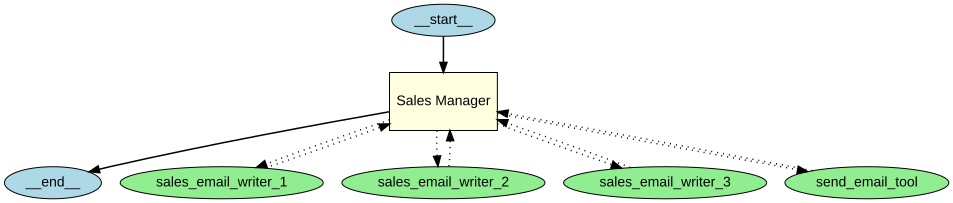

In [30]:
draw_graph(sales_manager_agent)

### 3.2: Via Handoffs

Orchestration Process:
1. Build a sales manager agent who has a team of email writers and a pick-and-sender
2. Provide email writes as tools, and sender_agent as handoffs

In [37]:
sales_manager_instructions2 = """
You are a sales manager at SoSafe. You have a team of email writers and an email-executor (picks and send emails).
"""
tools = [tool1, tool2, tool3]
handoffs = [sender_agent]
sales_manager2 = Agent(name = "SalesManager", instructions=sales_manager_instructions, tools=tools, handoffs= handoffs, model = MODEL_NAME)

In [38]:
task = """
You need to send a cold sales email. Use this workflow:
1. Use all your email writers and generate the email drafts. Just ask them to generate an email, and no additional details are necessary.
2. Handover the drafts to the sender_agent.
3. Give final response as short notes.
"""

with trace("Send email as handoff"):
    response = await Runner.run(sales_manager2, task)

print(response.final_output)

Sent the most balanced draft focused on reducing human risk without adding complexity.


# Exercise
Two exercises are suggested. The easy one is very simple and I see no learning in it, and the hard one is too much work, and I would spend that time on something more useful. So I will skip this ex, as I wrote the entire lab myself, that was already an exercise.